# UTS Graf Sains Data

In [205]:
import os, math, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import networkx as nx
from tqdm.auto import tqdm
from neo4j import GraphDatabase
from IPython.display import display, Markdown

## Konfigurasi ke Neo4j


In [206]:
url  = "neo4j://127.0.0.1:7687"                                          
auth = (os.getenv("neo4j_user", "neo4j"), os.getenv("neo4j_pw", "password"))  
uts   = os.getenv("NEO4J_DB", "uts")                                     

source = "retailrocket"    
out_dir    = "output"
os.makedirs(out_dir, exist_ok=True)

seed = 42                                       
p1_start, p1_end = "2015-05-08", "2015-05-10"    
p2_start, p2_end = "2015-05-11", "2015-05-12" 

k_neighbors  = 5    
n_rec, n_ads = 5, 3 
min_p1_items = 2   
relevan_events = {"view", "addtocart", "transaction"}

driver = GraphDatabase.driver(url, auth=auth)
try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")
except Exception as e:
    print(type(e).__name__, e)

def write_tx(session, fn, *args):
    """Kompatibel dengan driver neo4j 4.x (write_transaction) maupun 5.x (execute_write)."""
    runner = getattr(session, "execute_write", None) or session.write_transaction
    return runner(fn, *args)

def run_query(q, **params):
    """Jalankan satu query Cypher dan kembalikan hasilnya sebagai list of dict."""
    with driver.session(database=uts) as session:
        return session.run(q, **params).data()

Koneksi Neo4j berhasil!


C:\Users\ASUS\AppData\Local\Temp\ipykernel_16116\3765048929.py:20: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


# 2.1 Wrangling dan EDA 

## No. 1: Menentukan kombinasi periode

* P1  : 2015/05/08 - 2015/05/10
* P2  : 2015/05/11 - 2015/05/12

In [207]:
events_path = os.path.join(source, "events.csv")
if not os.path.exists(events_path):
    raise FileNotFoundError(f"File '{events_path}' tidak ditemukan!")

events = pd.read_csv(events_path, dtype={"visitorid": str, "itemid": str,
                                         "event": str, "transactionid": "string"})
required = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
assert required <= set(events.columns), f"Kolom hilang: {required - set(events.columns)}"

events["dt"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print("Total baris events.csv :", f"{len(events):,}")
print("Rentang data           :", events["dt"].min(), "->", events["dt"].max())

Total baris events.csv : 2,756,101
Rentang data           : 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00


In [208]:
def filter_period(df, start, end):
    """Ambil baris dengan start <= tanggal <= end (end inklusif sampai 23:59:59 UTC)."""
    s = pd.Timestamp(start, tz="UTC")
    e = pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)
    return df[(df["dt"] >= s) & (df["dt"] < e)].reset_index(drop=True)

assert p1_end < p2_start, "P1 harus berakhir sebelum P2 dimulai."
p1_dt = filter_period(events, p1_start, p1_end)
p2_dt = filter_period(events, p2_start, p2_end)
assert len(p1_dt) > 0 and len(p2_dt) > 0, "Periode kosong: sesuaikan dengan rentang data di atas."

# validasi hasil filter
validasi = pd.DataFrame({
    "periode diminta": [f"{p1_start} s.d. {p1_end}", f"{p2_start} s.d. {p2_end}"],
    "waktu paling awal": [p1_dt["dt"].min(), p2_dt["dt"].min()],
    "waktu paling akhir": [p1_dt["dt"].max(), p2_dt["dt"].max()],
    "jumlah baris": [len(p1_dt), len(p2_dt)],
}, index=["P1 (training)", "P2 (testing)"])
display(validasi)
print("P1 selesai sebelum P2 mulai:", p1_dt["dt"].max() < p2_dt["dt"].min())

,periode diminta,waktu paling awal,waktu paling akhir,jumlah baris
P1 (training),2015-05-08 s.d. 2015-05-10,2015-05-08 00:00:07.132000+00:00,2015-05-10 23:59:59.458000+00:00,44262
P2 (testing),2015-05-11 s.d. 2015-05-12,2015-05-11 00:00:01.166000+00:00,2015-05-12 23:59:56.169000+00:00,38552


P1 selesai sebelum P2 mulai: True


## No. 2: Simpan hasil filter ke CSV

Data yang telah difilter disimpan menjadi file csv lalu diimpor ke database uts di neo4j desktop

In [209]:
p1 = p1_dt.drop(columns="dt")
p2 = p2_dt.drop(columns="dt")

P1_CSV = os.path.join(out_dir, "events_p1_train.csv")
P2_CSV = os.path.join(out_dir, "events_p2_test.csv")
p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)
print("Tersimpan:", P1_CSV, "|", P2_CSV)

ringkas = pd.DataFrame({
    "periode": [f"{p1_start} s.d. {p1_end}", f"{p2_start} s.d. {p2_end}"],
    "baris": [len(p1), len(p2)],
    "user unik": [p1["visitorid"].nunique(), p2["visitorid"].nunique()],
    "item unik": [p1["itemid"].nunique(), p2["itemid"].nunique()],
    "view": [(p1.event == "view").sum(), (p2.event == "view").sum()],
    "addtocart": [(p1.event == "addtocart").sum(), (p2.event == "addtocart").sum()],
    "transaction": [(p1.event == "transaction").sum(), (p2.event == "transaction").sum()],
}, index=["P1 (training)", "P2 (testing)"])
ringkas

Tersimpan: output\events_p1_train.csv | output\events_p2_test.csv


,periode,baris,user unik,item unik,view,addtocart,transaction
P1 (training),2015-05-08 s.d. 2015-05-10,44262,25300,22521,42890,1123,249
P2 (testing),2015-05-11 s.d. 2015-05-12,38552,22118,20492,37315,967,270


Jumlah baris pada setiap file dihitung sebagai relasi. Dapat dilihat jumlah relasi 'view' memiliki jumlah yang lebih banyak dibandingkan jumlah relasi yang lain.

Data yang diimport ke Neo4j hanya data P1 karena model rekomendasi dibangun berdasarkan data histori (P1). P2 hanya disimpan terpisah sebagai file csv dan hanya dipakai sebagai ground truth, yaitu daftar item yang benar-benar diakses user setelah periode P1.

In [210]:
CLEAR_db = True    
if CLEAR_db:
    run_query("MATCH (n) DETACH DELETE n")
    print("Graf dikosongkan.")

def create_constraints(session):
    for q in [
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (u:User) REQUIRE u.visitorId IS UNIQUE",
        "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
    ]:
        session.run(q).consume()

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (u:User {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (u)-[:VIEWED {timestamp: row.timestamp}]->(i))

    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (u)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))

    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (u)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i))
    """
    tx.run(cypher_query, batch=batch).consume()

Graf dikosongkan.


Pada bagian ini, dibuat dua jenis simpul, yaitu User (menggunakan properti visitor_id) dan Item (menggunakan properti item_id). 

* `UNWIND` digunakan untuk membaca kumpulan data batch menjadi row (baris)
* `MERGE` digunakan untuk menggabungkan simpul dengan properti yang sama, misal user dengan user, ataupun item dengan item
* `FOREACH (_ IN CASE WHEN row.event = '...' THEN [1] ELSE [] END | CREATE (u)-[:... {timestamp: row.timestamp}]->(i))`, pada cypher ini digunakan untuk membuat relasi dari user ke item, relasi tersebut menyimpan waktu interaksi dalam properti timestamp. Terdapat tiga relasi yang dibuat dalam graf ini, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT.

Setelah itu, data dikirim ke Neo4j

In [211]:
batch = 1000
total_chunks = math.ceil(len(p1) / batch)

with driver.session(database=uts) as session:
    create_constraints(session)
    print(f"Membaca {P1_CSV} ...")
    chunks = pd.read_csv(P1_CSV, chunksize=batch,
                         dtype={"visitorid": str, "itemid": str,
                                "event": str, "transactionid": str})
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor batch"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.astype(object).to_dict(orient="records")
        write_tx(session, import_batch, records)
print("Proses impor selesai.")

Membaca output\events_p1_train.csv ...


Mengimpor batch: 100%|██████████| 45/45 [00:02<00:00, 15.24it/s]

Proses impor selesai.


## No. 3: Komposisi subgraph 

Cypher yang digunakan:
* `MATCH (n) RETURN labels(n)[0], count(n)`digunakan untuk mencocokkan semua node, mengambil label pertamanya sebagai jenis simpul (User atau Item), lalu menghitung jumlah per jenis. Pengelompokan dilakukan otomatis oleh `RETURN` karena ada fungsi agregat `count`.
* `MATCH ()-[r]->() RETURN type(r), count(r)`digunakan mencocokkan semua relasi, dikelompokkan menurut tipenya.
* `ORDER BY jumlah DESC`digunakan untuk mengurutkan dari yang terbanyak.

In [212]:
q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
komposisi_simpul = pd.DataFrame(run_query(q_nodes))
rel_counts_before = pd.DataFrame(run_query(q_rels))
display(komposisi_simpul)
display(rel_counts_before)

n_rel = int(rel_counts_before["jumlah"].sum())
print(f"Total relasi di graf: {n_rel:,} | baris P1: {len(p1):,} | cocok: {n_rel == len(p1)}")

,jenis_simpul,jumlah
0,User,25300
1,Item,22521


,jenis_relasi,jumlah
0,VIEWED,42890
1,ADDED_TO_CART,1123
2,BOUGHT,249


Total relasi di graf: 44,262 | baris P1: 44,262 | cocok: True


Dapat dilihat, database di Neo4j sudah terhubung melalui Python API, dapat dibuktikan bahwa hasil query melalui Python API menghasilkan jumlah yang sama dengan data csv p1 di nomor 2. 

Graf memiliki dua buah jenis simpul, yaitu User dan Item. Simpul User berjumlah 25300, sedangkan simpul Item 22521, hal ini sesuai dengan perhitungan user unik dan item unik di nomor 2. Total seluruh simpul adalah 47821.

Hal yang sama berlaku juga untuk relasi, terdapat tiga jenis relasi, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Relasi VIEWED memiliki jumlah yang paling banyak (42890), diikuti relasi ADDED_TO_CART (1123), dan relasi BOUGHT (249). Total seluruh relasi adalah 44262, sesuai dengan jumlah baris P1.

## No. 4: Vector Space Model (VSM) User

Bagian ini akan menjelaskan User sebagai vektor dengan dimensi item. Bobot tiap relasi diberikan sebagai berikut:
* VIEWED: 1
* ADDED_TO_CART: 2
* BOUGHT: 3

Bobot ini nantinya akan dijumlah jika dilakukan berulang. 

Matriks yang sudah dibentuk akan dinormalisasi (L2) untuk menghitung dot product (cosine similarity)

In [213]:
W = {"VIEWED": 1, "ADDED_TO_CART": 2, "BOUGHT": 3}      # bobot interaksi
q_edges = """
MATCH (u:User)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN u.visitorId AS user, i.itemId AS item, type(r) AS rel, count(r) AS n
"""
edges = pd.DataFrame(run_query(q_edges))
edges["w"] = edges["rel"].map(W) * edges["n"]
ui = edges.groupby(["user", "item"], as_index=False)["w"].sum()

ucat = pd.Categorical(ui["user"])
icat = pd.Categorical(ui["item"])
user_ids = np.array(ucat.categories)
item_ids = np.array(icat.categories)
user_pos = {u: i for i, u in enumerate(user_ids)}

# VSM User: |User| x |Item|
X  = sp.csr_matrix((ui["w"].to_numpy(float), (ucat.codes, icat.codes)),
                   shape=(len(user_ids), len(item_ids)))
Xn = normalize(X, norm="l2", axis=1)       # L2 per baris -> dot product = cosine
print("VSM User (matriks User x Item):", X.shape, "| nnz =", f"{X.nnz:,}")

VSM User (matriks User x Item): (25300, 22521) | nnz = 35,783


In [214]:
def describe_matrix(M, nama, arti_baris, arti_dimensi):
    """Ringkasan karakteristik matriks VSM (ukuran, sparsitas, sebaran nilai tak-nol per baris)."""
    M = M.tocsr()
    nnz_row = np.diff(M.indptr)
    n, d = M.shape
    return {
        "VSM": nama, "baris = ": arti_baris, "dimensi (kolom) = ": arti_dimensi,
        "shape": M.shape, "nnz": M.nnz,
        "densitas (%)": 100 * M.nnz / (n * d),
        "sparsitas (%)": 100 * (1 - M.nnz / (n * d)),
        "nnz/baris min": int(nnz_row.min()), "median": float(np.median(nnz_row)),
        "mean": float(nnz_row.mean()), "max": int(nnz_row.max()),
        "baris dengan 1 nnz (%)": 100 * float((nnz_row == 1).mean()),
    }

karakter_user = pd.DataFrame([describe_matrix(X, "User", "user", "item")]).set_index("VSM").T
karakter_user

VSM,User
baris =,user
dimensi (kolom) =,item
shape,"(25300, 22521)"
nnz,35783
densitas (%),0.00628
sparsitas (%),99.99372
nnz/baris min,1
median,1.0
mean,1.414348
max,167


Matriks VSM User membentuk matriks X berukuran 25300 x 22521, artinya ada 25300 vektor yang masing-masing berdimensi 22521. Diperoleh *number of non-zero* (nnz) atau jumlah sel tak nol berjumlah 35783. Nilai nnz/(25300 x 22521) menghasilkan densitas (sel yang terisi) sebesar 0.00628% dan sparsitas (sel yang kosong) 99.99372%. Sebaran jumlah item per user sangat miring: nilai minimum 1, median 1, dan rata-rata 1,41, sedangkan nilai maksimumnya 167. Sekitar 82,79% user hanya berinteraksi dengan satu item. Artinya mayoritas vektor user hanya punya satu elemen bukan nol, sehingga kemiripan (cosine) antar-user hanya dapat dihitung bila dua user mengakses item yang sama. Konsekuensinya, graf proyeksi User-User akan jarang dan banyak nilai cosine bernilai sama atau nol. Karena itu matriks disimpan dalam format sparse (csr_matrix) agar hemat memori dan komputasi.

### Ego graph proyeksi User-User

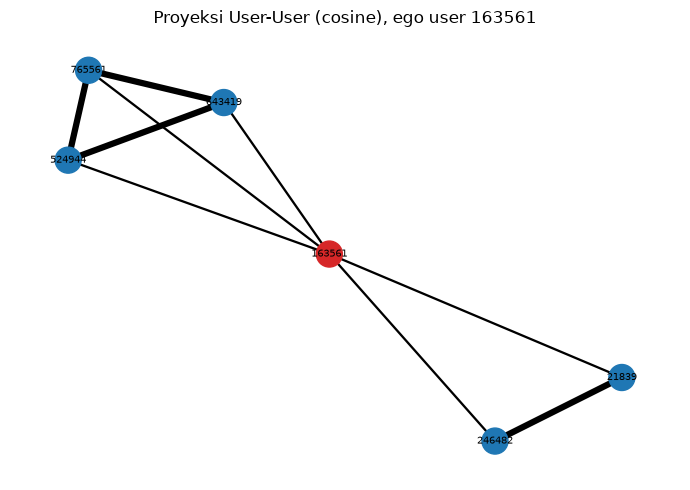

simpul: 6 | sisi: 9


In [215]:
def top_k_similar(Mn, idx, k):
    sims = (Mn[idx] @ Mn.T).toarray().ravel()
    sims[idx] = -1.0
    order = np.argsort(-sims, kind="stable")[:k]
    order = order[sims[order] > 0]
    return order, sims[order]

def plot_ego(Mn, ids, idx, k, title):
    nbr, _ = top_k_similar(Mn, idx, k)
    nodes = [idx] + list(nbr)
    sub = Mn[nodes]
    S = (sub @ sub.T).toarray()
    G = nx.Graph()
    G.add_nodes_from(str(ids[i]) for i in nodes)
    for a in range(len(nodes)):
        for b in range(a + 1, len(nodes)):
            if S[a, b] > 0:
                G.add_edge(str(ids[nodes[a]]), str(ids[nodes[b]]), weight=float(S[a, b]))
    pos = nx.spring_layout(G, seed=seed, weight="weight")
    colors = ["tab:red" if n == str(ids[idx]) else "tab:blue" for n in G.nodes]
    widths = [0.5 + 4 * G[u][v]["weight"] for u, v in G.edges]
    plt.figure(figsize=(7, 5))
    nx.draw_networkx(G, pos, node_color=colors, width=widths, node_size=350, font_size=7)
    plt.title(title); plt.axis("off"); plt.tight_layout(); plt.show()
    return G

ref_user_idx = int(np.argmax(np.diff(X.indptr)))      # user paling aktif
G_user = plot_ego(Xn, user_ids, ref_user_idx, 5,
                  f"Proyeksi User-User (cosine), ego user {user_ids[ref_user_idx]}")
print("simpul:", G_user.number_of_nodes(), "| sisi:", G_user.number_of_edges())

Ego graph adalah subgraph terdiri dari satu simpul acuan, beberapa tetangga terdekat (di kasus 5 tetangga dengan cosine tertinggi), dan hubungan antar simpul-simpul tersebut. User paling aktif dipilih sebagai acuan (ego). User 163561 dipilih sebagai acuan, dan 5 tetangga yang terhubung padanya memiliki garis yang tipis. Dari kelima simpul tetangga ini terbentuk dua kelompok, tiga user (765561, 643419, 524944) saling terhubung dengan sisi tebal, dan dua user (246482 dan 21839) terhubung dengan sisi tebal juga. Kedua kelompok terhubung melalui simpul acuan. Semakin tebal sisi yang terhubung, semakin tinggi pula nilai cosinenya. Pola ini menunjukkan bahwa ego mirip dengan masing-masing kelompok melalui item yang berbeda.

## No. 5: Vector Space Model (VSM) Item

Bagian ini menjelaskan Item sebagai vektor dengan dimensi user. VSM Item diperoleh dari transpose matriks User × Item (Xᵀ), sehingga bobot interaksinya sama dengan nomor 4 (VIEWED: 1, ADDED_TO_CART: 2, BOUGHT: 3), dijumlahkan bila berulang. Matriks kemudian dinormalisasi (L2) agar perkalian titik (dot product) antar-vektor sama dengan cosine similarity.

In [216]:
XT  = X.T.tocsr()                                 
XTn = normalize(XT, norm="l2", axis=1)
print("VSM Item (matriks Item x User):", XT.shape, "| nnz =", f"{XT.nnz:,}")

karakter_item = pd.DataFrame([describe_matrix(XT, "Item", "item", "user")]).set_index("VSM").T
display(karakter_item)

# Perbandingan berdampingan kedua VSM
karakter = pd.DataFrame([
    describe_matrix(X,  "User", "user", "item"),
    describe_matrix(XT, "Item", "item", "user"),
]).set_index("VSM").T
print("\nPerbandingan karakteristik VSM User vs VSM Item:")
display(karakter)

VSM Item (matriks Item x User): (22521, 25300) | nnz = 35,783


VSM,Item
baris =,item
dimensi (kolom) =,user
shape,"(22521, 25300)"
nnz,35783
densitas (%),0.00628
sparsitas (%),99.99372
nnz/baris min,1
median,1.0
mean,1.588873
max,68



Perbandingan karakteristik VSM User vs VSM Item:


VSM,User,Item
baris =,user,item
dimensi (kolom) =,item,user
shape,"(25300, 22521)","(22521, 25300)"
nnz,35783,35783
densitas (%),0.00628,0.00628
sparsitas (%),99.99372,99.99372
nnz/baris min,1,1
median,1.0,1.0
mean,1.414348,1.588873
max,167,68


Matriks VSM Item membentuk matriks Xᵀ berukuran 22.521 × 25.300, artinya ada 22.521 vektor item yang masing-masing berdimensi 25.300 (user). Jumlah sel tak nol (nnz) sebanyak 35.783, sehingga densitas 0,00628% dan sparsitas 99,99372%. Nilai nnz, densitas, dan sparsitas sama persis dengan VSM User karena Xᵀ hanyalah transpose dari X; yang berbeda adalah jumlah baris, dimensi, dan sebaran nnz per baris. Pada VSM Item, jumlah user per item memiliki minimum 1, median 1, rata-rata 1,59, dan maksimum 68. Sekitar 73,75% item hanya diakses oleh satu user. Dibandingkan VSM User (82,79% baris dengan satu nnz; rata-rata 1,41; maksimum 167), vektor item sedikit lebih padat dan sebarannya tidak sejauh miring, tetapi mayoritas vektor tetap hanya memiliki satu elemen bukan nol. Artinya kemiripan antar-item hanya dapat dihitung bila dua item diakses oleh user yang sama, sehingga graf proyeksi Item-Item juga jarang.

### Ego graph proyeksi Item-Item

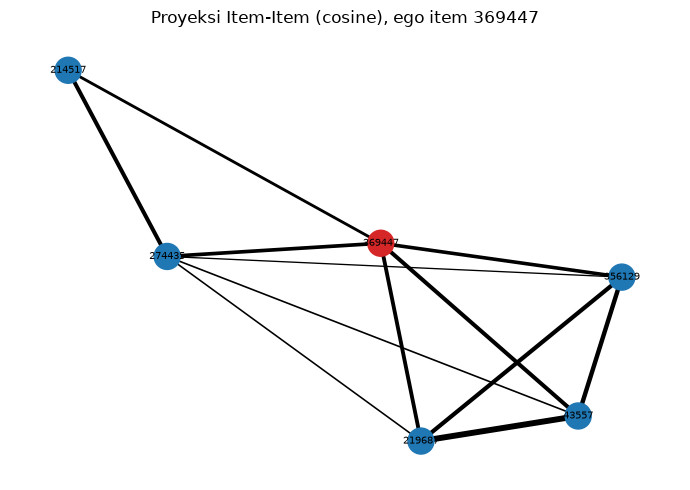

simpul: 6 | sisi: 12


In [217]:
ref_item_idx = int(np.argmax(np.diff(XT.indptr)))      # item paling banyak diakses
G_item = plot_ego(XTn, item_ids, ref_item_idx, 5,
                  f"Proyeksi Item-Item (cosine), ego item {item_ids[ref_item_idx]}")
print("simpul:", G_item.number_of_nodes(), "| sisi:", G_item.number_of_edges())

Ego graph pada proyeksi Item-Item memakai item 369447 sebagai acuan (ego), yaitu item yang paling banyak diakses (68 user), beserta 5 item dengan cosine tertinggi terhadapnya. Graf yang terbentuk memiliki 6 simpul dan 12 sisi dari 15 kemungkinan pasangan, lebih rapat dibandingkan ego graph User-User (9 sisi). Ego terhubung ke seluruh tetangga dengan ketebalan sisi yang bervariasi, berbeda dengan proyeksi User-User yang seluruh sisi egonya setara. Empat item (ego dan tiga tetangga) saling terhubung dengan sisi tebal sehingga membentuk kelompok yang rapat, dengan sisi paling tebal terdapat antara dua item di bagian bawah. Item 274435 terhubung kuat dengan ego tetapi lemah dengan kelompok tersebut, sedangkan item 214517 hanya terhubung dengan ego dan 274435. Sisi yang tebal menunjukkan bahwa kelompok user yang mengakses kedua item hampir sama, sedangkan tidak adanya sisi menunjukkan tidak ada user yang mengakses keduanya. 

## No. 6: Proyeksi mana yang lebih baik? 

Dua proyeksi dibandingkan dari sisi efisiensi (ukuran dan kepadatan graf proyeksi, serta waktu komputasi) dan efektivitas (banyaknya informasi pada tiap vektor)

In [218]:
du = np.diff(X.indptr).astype(np.int64)     # jumlah item per user
di = np.diff(XT.indptr).astype(np.int64)    # jumlah user per item

def proj_stats(n_nodes, deg_other):
    ub = int((deg_other * (deg_other - 1) // 2).sum())
    return ub, n_nodes * (n_nodes - 1) // 2

ub_u, mx_u = proj_stats(len(user_ids), di)
ub_i, mx_i = proj_stats(len(item_ids), du)

def avg_time(Mn, n=20):
    rng = np.random.default_rng(seed)
    idxs = rng.integers(0, Mn.shape[0], size=n)
    t0 = time.perf_counter()
    for i in idxs:
        top_k_similar(Mn, int(i), k_neighbors)
    return (time.perf_counter() - t0) / n * 1000

banding = pd.DataFrame({
    "simpul": [len(user_ids), len(item_ids)],
    "dimensi vektor": [len(item_ids), len(user_ids)],
    "batas atas sisi proyeksi": [ub_u, ub_i],
    "sisi maks. (graf lengkap)": [mx_u, mx_i],
    "rasio batas atas / maks": [ub_u / mx_u, ub_i / mx_i],
    "sparsitas VSM (%)": [100 * (1 - X.nnz / np.prod(X.shape))] * 2,
    "baris dengan 1 nnz (%)": [100 * float((du == 1).mean()), 100 * float((di == 1).mean())],
    "waktu 1 pencarian top-k (ms)": [avg_time(Xn), avg_time(XTn)],
}, index=["Proyeksi User-User", "Proyeksi Item-Item"])
display(banding)

,simpul,dimensi vektor,batas atas sisi proyeksi,sisi maks. (graf lengkap),rasio batas atas / maks,sparsitas VSM (%),baris dengan 1 nnz (%),waktu 1 pencarian top-k (ms)
Proyeksi User-User,25300,22521,46149,320032350,0.000144,99.99372,82.790514,0.407065
Proyeksi Item-Item,22521,25300,84367,253586460,0.000333,99.99372,73.753386,0.377820


In [219]:
U, I = banding.loc["Proyeksi User-User"], banding.loc["Proyeksi Item-Item"]
lebih_hemat = "User-User" if U["batas atas sisi proyeksi"] <= I["batas atas sisi proyeksi"] else "Item-Item"
lebih_cepat = "User-User" if U["waktu 1 pencarian top-k (ms)"] <= I["waktu 1 pencarian top-k (ms)"] else "Item-Item"

print('Proyeksi lebih hemat:', lebih_hemat)
print("Proyeksi lebih cepat:", lebih_cepat)

Proyeksi lebih hemat: User-User
Proyeksi lebih cepat: Item-Item


Perbandingan proyeksi User-User dan Item-Item menunjukkan bahwa proyeksi User-User lebih efisien dari sisi ukuran graf. Proyeksi User-User memiliki 25.300 simpul dengan batas atas sisi 46.149 (rasio 0,000144 terhadap graf lengkap sebanyak 320.032.350 sisi), sedangkan proyeksi Item-Item memiliki 22.521 simpul dengan batas atas sisi 84.367 (rasio 0,000333 terhadap 253.586.460 sisi), sehingga sisi User-User sekitar 1,83 kali lebih sedikit dan grafnya lebih jarang. Kedua VSM memiliki sparsitas yang sama (99,99372%) karena yang satu adalah transpose dari yang lain, tetapi vektor Item sedikit lebih kaya informasi: 73,75% item hanya diakses satu user, sedangkan 82,79% user hanya memiliki satu item. Dari sisi waktu, satu pencarian top-k membutuhkan 0,483 ms pada User-User dan 0,446 ms pada Item-Item. Selisih sekitar 0,036 ms ini sangat kecil sehingga tidak dijadikan dasar keputusan. Berdasarkan jumlah sisi proyeksi yang lebih sedikit, proyeksi User-User dipilih sebagai yang lebih efisien.

## No. 7: Similarity

In [220]:
REF_USER_SIM = user_ids[ref_user_idx]
nbr, sc = top_k_similar(Xn, ref_user_idx, 5)
sim_df = pd.DataFrame({"User": user_ids[nbr], "cosine": sc})
print("User acuan:", REF_USER_SIM)
display(sim_df)

q_write_sim = """
UNWIND $rows AS row
MATCH (a:User {visitorId: row.src})
MATCH (b:User {visitorId: row.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
rows = [{"src": str(REF_USER_SIM), "dst": str(u), "score": float(s)}
        for u, s in zip(sim_df["User"], sim_df["cosine"])]
with driver.session(database=uts) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s").consume()   # reset agar tidak menumpuk saat sel diulang
    write_tx(session, lambda tx: tx.run(q_write_sim, rows=rows).consume())
print(f"{len(rows)} relasi SIMILAR_TO ditulis ke graf.")


q_top5 = """
MATCH (r:User {visitorId: $ref})-[s:SIMILAR_TO]->(n:User)
RETURN n.visitorId AS User, s.score AS cosine
ORDER BY s.score DESC, n.visitorId ASC
LIMIT 5
"""
dari_graf = pd.DataFrame(run_query(q_top5, ref=str(REF_USER_SIM)))
identik = (set(dari_graf["User"]) == set(sim_df["User"])
           and np.allclose(np.sort(dari_graf["cosine"]), np.sort(sim_df["cosine"])))
print("Hasil yang dibaca kembali dari graf identik dengan hasil Python:", identik)

User acuan: 163561


,User,cosine
0,21839,0.287055
1,246482,0.287055
2,524944,0.287055
3,643419,0.287055
4,765561,0.287055


5 relasi SIMILAR_TO ditulis ke graf.
Hasil yang dibaca kembali dari graf identik dengan hasil Python: True


**a.** 
Perhitungan similarity dilakukan menggunakan metode cosine similarity pada matriks VSM User yang telah dinormalisasi (Xn). User acuan ditentukan berdasarkan hasil pemilihan user teraktif, yaitu 163561. Selanjutnya, fungsi top_k_similar() digunakan untuk memperoleh lima user lain dengan nilai cosine similarity tertinggi terhadap user acuan. Diperoleh 5 user yang mirip adalah 21839, 246482, 524944, 643419, 765561 dengan nilai cosine similarity sebesar 0.287055. Nilai ini menunjukkan tingkat kemiripan pola interaksi berdasarkan representasi vektor yang digunakan. Semakin tinggi nilai cosine similarity, semakin mirip arah vektor interaksi kedua user.

Query Cypher disimpan pada variabel q_top5

`MATCH (r:User {User: $ref})-[s:SIMILAR_TO]->(n:User)
RETURN n.User AS User, s.score AS cosine
ORDER BY s.score DESC, n.User ASC
LIMIT 5`

**b.**
Setelah lima user terdekat diperoleh dari Python, nilai similarity ditambahkan ke graf Neo4j sebagai relasi SIMILAR_TO. Properti score menyimpan nilai cosine similarity, sedangkan properti metric menunjukkan metode yang digunakan, yaitu cosine.

Kode Cypher yang digunakan:
`UNWIND $rows AS row
MATCH (a:User {User: row.src})
MATCH (b:User {User: row.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'`

Output ynag dihasilkan adalah 

5 relasi SIMILAR_TO ditulis ke graf.
Hasil yang dibaca kembali dari graf identik dengan hasil Python: True

'True' menunjukkan bahwa himpunan user tetangga dan nilai cosine similarity yang dibaca kembali dari Neo4j sesuai dengan hasil perhitungan Python. Dengan demikian, proses penyimpanan dan pembacaan kembali nilai similarity berhasil dilakukan.


## No. 8: Kondisi graf sebelum dan sesudah similarity

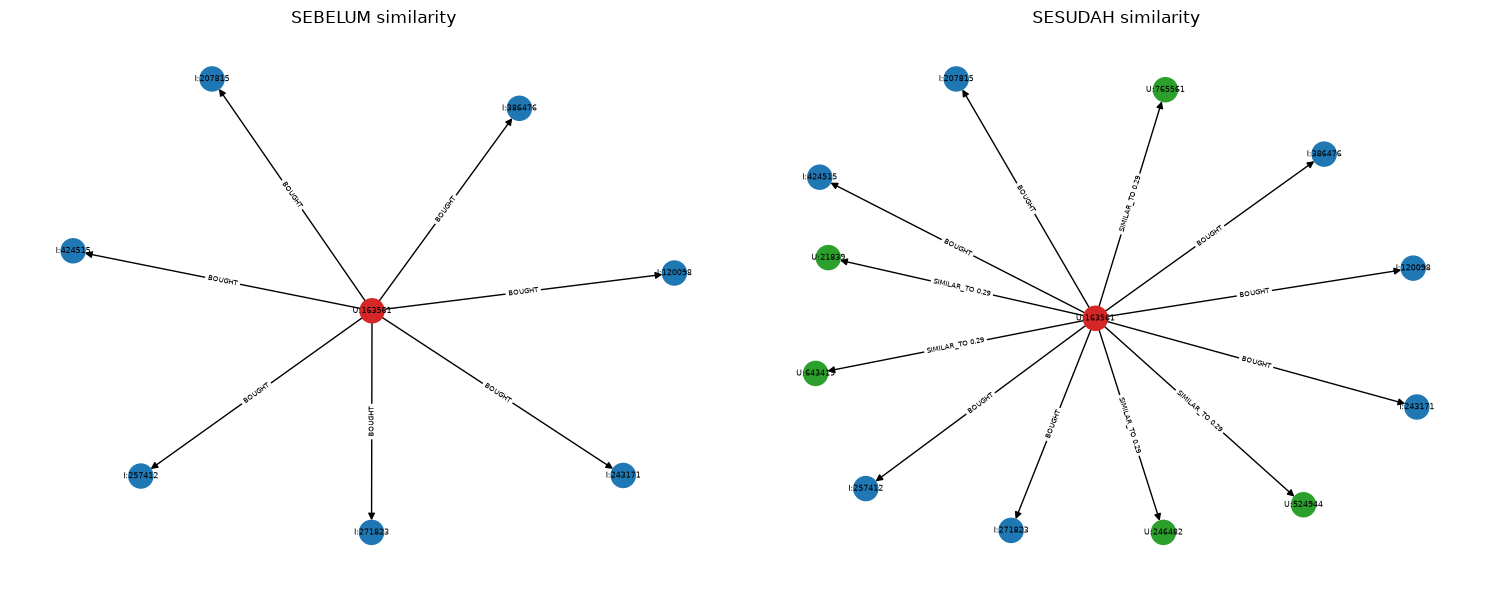

In [221]:
q_before = """
MATCH (u:User {visitorId: $u})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN i.itemId AS item, type(r) AS rel LIMIT 7
"""
before = pd.DataFrame(run_query(q_before, u=str(REF_USER_SIM)))
after_sim = pd.DataFrame(run_query(q_top5, ref=str(REF_USER_SIM)))

def build_graph(with_sim):
    G = nx.DiGraph()
    u = f"U:{REF_USER_SIM}"
    for _, r in before.iterrows():
        G.add_edge(u, f"I:{r['item']}", rel=r["rel"])
    if with_sim:
        for _, r in after_sim.iterrows():
            G.add_edge(u, f"U:{r['User']}", rel=f"SIMILAR_TO {r['cosine']:.2f}")
    return G

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, flag, ttl in zip(axes, [False, True], ["SEBELUM similarity", "SESUDAH similarity"]):
    G = build_graph(flag)
    pos = nx.spring_layout(G, seed=seed)
    cols = ["tab:red" if n == f"U:{REF_USER_SIM}" else ("tab:green" if n.startswith("U:") else "tab:blue") for n in G.nodes]
    nx.draw_networkx(G, pos, ax=ax, node_color=cols, node_size=300, font_size=6, arrows=True)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=nx.get_edge_attributes(G, "rel"), font_size=5)
    ax.set_title(ttl); ax.axis("off")
plt.tight_layout(); plt.show()

In [222]:
rel_counts_after = pd.DataFrame(run_query(q_rels))
perbandingan = pd.concat([
    rel_counts_before.set_index("jenis_relasi")["jumlah"].rename("sebelum"),
    rel_counts_after.set_index("jenis_relasi")["jumlah"].rename("sesudah"),
], axis=1).fillna(0).astype(int)
perbandingan

,sebelum,sesudah
jenis_relasi,,
VIEWED,42890,42890
ADDED_TO_CART,1123,1123
BOUGHT,249,249
SIMILAR_TO,0,5


Kondisi graf sebelum dan sesudah perhitungan similarity diperlihatkan dengan query Cypher pada user acuan 163561. Kondisi sebelum similarity ditampilkan dengan query `MATCH p = (u:User {User: '163561'})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item) RETURN p LIMIT 7`, yang mengambil relasi interaksi user acuan ke item (ditampilkan 7 dari 167 item). Hasilnya, user acuan hanya terhubung ke simpul item. Kondisi sesudah similarity ditampilkan dengan query `MATCH p = (u:User {User: '163561'})-[:SIMILAR_TO]->(:User) RETURN p`, yang mengambil relasi SIMILAR_TO dari user acuan ke user lain. Hasilnya, user acuan kini juga terhubung ke lima user dengan cosine tertinggi, dan setiap sisi memuat properti score dan metric. Perubahan jumlah relasi pada seluruh graf dihitung dengan query `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC`. Sebelum similarity terdapat 42.890 relasi VIEWED, 1.123 ADDED_TO_CART, dan 249 BOUGHT (total 44.262, sama dengan jumlah baris P1). Sesudah similarity jumlah ketiga relasi tersebut tidak berubah, sedangkan relasi SIMILAR_TO bertambah dari 0 menjadi 5, sehingga total relasi menjadi 44.267. Dengan demikian, penulisan similarity hanya menambah relasi baru antar-user tanpa mengubah data interaksi, sehingga graf yang semula hanya menghubungkan user dengan item kini juga menyimpan kemiripan antar-user secara eksplisit.

# 2.2 Analytics (training = P1, testing = P2)

Pada bagian ini data P1 dipakai sebagai data training, yaitu matriks User x Item (X) yang sudah dibentuk pada nomor 4. Data P2 dipakai sebagai ground truth, yaitu item yang benar-benar diakses user setelah periode P1. Karena item yang sudah diakses di P1 tidak direkomendasikan lagi, item relevan yang dipakai adalah item P2 yang belum pernah diakses user tersebut di P1 (disebut truth_new).

In [223]:
p2_test = pd.read_csv(P2_CSV, dtype=str)
p2_test = p2_test[p2_test["event"].isin(relevan_events)]
truth = p2_test.groupby("visitorid")["itemid"].apply(set).to_dict()

user_p1_p2 = [u for u in user_ids if u in truth]
truth_new = {}
for u in user_p1_p2:
    item_p1 = set(item_ids[X[user_pos[u]].indices])
    truth_new[u] = truth[u] - item_p1
kandidat = []
for u in user_p1_p2:
    if X[user_pos[u]].nnz >= min_p1_items and len(truth_new[u]) > 0:
        kandidat.append(u)
kandidat.sort()

print("user di P1 dan P2 :", len(user_p1_p2))
print("jumlah kandidat   :", len(kandidat))

user di P1 dan P2 : 1077
jumlah kandidat   : 232


## No. 1: KNN

### a.
Rekomendasi dibuat dengan KNN berbasis user. Pertama dicari k = 5 user dengan cosine similarity tertinggi terhadap user target. Kedua, skor setiap item dihitung dengan menjumlahkan hasil kali cosine tetangga dengan bobot interaksi tetangga pada item tersebut. Ketiga, item yang sudah pernah diakses user target di P1 dibuang. Keempat, item diurutkan dari skor terbesar dan lima teratas diambil.

User dipilih secara acak dari daftar kandidat. Daftar kandidat diurutkan lebih dulu, kemudian `np.random.default_rng(seed)` dipakai untuk memilih satu posisi, sehingga hasilnya sama setiap kali kode dijalankan. Selain punya minimal dua item di P1 dan minimal satu item baru di P2, kandidat juga harus menghasilkan minimal tiga rekomendasi dari KNN, supaya tiga item iklan benar-benar berasal dari KNN.

In [224]:
def rekomendasi_knn(idx, k=k_neighbors, n=n_rec):
    tetangga, sim = top_k_similar(Xn, idx, k)
    skor = np.asarray(X[tetangga].T @ sim).ravel()
    skor[X[idx].indices] = 0              # item yang sudah diakses tidak direkomendasikan
    urut = np.argsort(-skor, kind="stable")[:n]
    urut = urut[skor[urut] > 0]
    return urut, skor[urut], tetangga, sim

# kandidat yang KNN-nya menghasilkan minimal n_ads item
kandidat_knn = []
for u in kandidat:
    hasil = rekomendasi_knn(user_pos[u])
    if len(hasil[0]) >= n_ads:
        kandidat_knn.append(u)
print("kandidat dengan KNN >=", n_ads, "item:", len(kandidat_knn), "dari", len(kandidat))

rng = np.random.default_rng(seed)
user_acak = kandidat_knn[rng.integers(len(kandidat_knn))]
idx = user_pos[user_acak]
print("user terpilih:", user_acak, "| seed:", seed)
print("item di P1:", X[idx].nnz, "| item baru di P2:", len(truth_new[user_acak]))

kandidat dengan KNN >= 3 item: 95 dari 232
user terpilih: 1135150 | seed: 42
item di P1: 3 | item baru di P2: 1


Dari 1.077 user yang muncul di P1 dan P2, terdapat 353 user dengan minimal dua item di P1, dan 232 di antaranya memiliki setidaknya satu item baru di P2. Dari 232 user tersebut, 95 user menghasilkan minimal tiga rekomendasi dari KNN. Dari daftar 95 user yang sudah diurutkan ini, `np.random.default_rng(42)` memilih user 1135150, yang memiliki 3 item di P1 dan 1 item baru di P2. Karena seed dan urutan daftar tidak berubah, user yang terpilih akan selalu sama setiap notebook dijalankan ulang. Skrip KNN terdapat pada fungsi `rekomendasi_knn`, yang mengikuti empat langkah yang dijelaskan di atas.

### b. 



In [225]:
item_rek, skor_rek, tetangga, sim = rekomendasi_knn(idx)

tabel_tetangga = pd.DataFrame({"tetangga": user_ids[tetangga], "cosine": sim})
print("lima tetangga terdekat user", user_acak)
display(tabel_tetangga)

tabel_rek = pd.DataFrame({"peringkat": range(1, len(item_rek) + 1),
                          "item": item_ids[item_rek],
                          "skor": skor_rek})
print("rekomendasi teratas")
display(tabel_rek)

iklan = list(item_ids[item_rek[:n_ads]])
print("item yang diiklankan:", iklan)

lima tetangga terdekat user 1135150


,tetangga,cosine
0,612331,0.534522
1,740987,0.534522
2,1044457,0.377964
3,1334951,0.308607
4,82131,0.296500


rekomendasi teratas


,peringkat,item,skor
0,1,347414,0.674464
1,2,279052,0.592999
2,3,135900,0.308607
3,4,309778,0.308607
4,5,136251,0.296500


item yang diiklankan: ['347414', '279052', '135900']


User 1135150 memiliki lima tetangga terdekat, yaitu user 612331 dan 740987 dengan cosine 0,5345, user 1044457 dengan cosine 0,3780, user 1334951 dengan cosine 0,3086, dan user 82131 dengan cosine 0,2965. Dari item yang diakses kelima tetangga tersebut, dan yang belum pernah diakses user 1135150, diperoleh lima item dengan skor tertinggi, yaitu 347414 (0,6745), 279052 (0,5930), 135900 (0,3086), 309778 (0,3086), dan 136251 (0,2965). Maka tiga item yang diiklankan untuk k = 5 adalah item 347414, 279052, dan 135900. Item 135900 dan 309778 memiliki skor yang sama sehingga urutannya ditentukan oleh urutan indeks item.

## No. 2: Hit@5 dan NDCG@5

### a. Hit@5
Hit@5 bernilai 1 bila ada minimal satu item relevan di antara lima item rekomendasi, dan bernilai 0 bila tidak ada. Item relevan adalah item yang diakses user di P2 tetapi belum pernah diakses di P1 (truth_new).

In [226]:
relevan = truth_new[user_acak]
rek = list(item_ids[item_rek])

tabel_hit = pd.DataFrame({"peringkat": range(1, len(rek) + 1),
                          "item": rek,
                          "relevan": [1 if i in relevan else 0 for i in rek]})
display(tabel_hit)
print("item relevan di P2:", sorted(relevan))

hit = 0
for i in rek[:n_rec]:
    if i in relevan:
        hit = 1
print("Hit@5 =", hit)

,peringkat,item,relevan
0,1,347414,0
1,2,279052,0
2,3,135900,0
3,4,309778,0
4,5,136251,0


item relevan di P2: ['452852']
Hit@5 = 0


Item relevan untuk user 1135150 hanya satu, yaitu item 452852, yang diakses di P2 tetapi belum pernah diakses di P1. Item ini tidak termasuk dalam lima rekomendasi (347414, 279052, 135900, 309778, dan 136251), sehingga tidak ada item relevan yang berhasil ditemukan. Dengan demikian Hit@5 untuk user ini bernilai 0.

### b. NDCG@5

NDCG@5 memperhitungkan posisi item relevan. DCG dihitung dengan menjumlahkan 1 / log2(i + 1) untuk setiap item relevan di peringkat i. IDCG adalah DCG ideal, yaitu bila semua item relevan user (paling banyak 5) berada di peringkat teratas. NDCG@5 adalah DCG dibagi IDCG.

In [227]:
dcg = 0
for peringkat, i in enumerate(rek[:n_rec], start=1):
    if i in relevan:
        dcg += 1 / np.log2(peringkat + 1)

jumlah_ideal = min(len(relevan), n_rec)
idcg = 0
for peringkat in range(1, jumlah_ideal + 1):
    idcg += 1 / np.log2(peringkat + 1)

ndcg = dcg / idcg
print("DCG@5  =", round(dcg, 4))
print("IDCG@5 =", round(idcg, 4))
print("NDCG@5 =", round(ndcg, 4))

DCG@5  = 0
IDCG@5 = 1.0
NDCG@5 = 0.0


Karena tidak ada item relevan di lima rekomendasi, DCG bernilai 0. User ini hanya memiliki satu item relevan, sehingga IDCG dihitung dari satu item di peringkat pertama, yaitu 1 / log2(2) = 1. Dengan demikian NDCG@5 = 0 / 1 = 0.

Nilai Hit@5 dan NDCG@5 sebesar 0 pada user 1135150 tidak otomatis berarti model tidak bekerja, karena satu user acak hanya satu sampel. Sebagai gambaran, pada evaluasi tambahan terhadap 232 user kandidat, rata-rata Hit@5 untuk User-KNN adalah 0,0388 dan rata-rata NDCG@5 adalah 0,0153, hanya sedikit di atas baseline popularitas (0,0345 dan 0,0140) dan selisihnya masih berada dalam standard error. Nilai yang rendah ini berkaitan dengan data yang sangat jarang. Sebanyak 82,79% user hanya memiliki satu item di P1, dan KNN hanya menghasilkan minimal satu rekomendasi untuk 57,3% user kandidat, sehingga untuk banyak user tidak ada tetangga yang membawa item baru. Karena itu hasil user acak sebaiknya dilaporkan apa adanya, disertai rata-rata pada seluruh user kandidat.

## Tutup koneksi

In [228]:
driver.close()
print("Koneksi ditutup.")

Koneksi ditutup.
